# Phase 5 — Hypothesis Testing (H1, H2) with a Paired Customer-Level Bootstrap

**Proposal section:** 3.7 Model Evaluation and Hypothesis Testing
**Input:** `data/processed/phase4_test_predictions.parquet` (test origins S6–S7, 8,983 rows, 4,680 customers)
**Outputs:** `outputs/tables/phase5_*.csv`, `outputs/figures/phase5_*.png`

**Hypotheses**
- **H1:** for the same classifier, Config B (with historical states) has a higher Macro-F1 than Config A: Δ_c = Macro-F1(B, c) − Macro-F1(A, c) > 0.
- **H2:** Δ differs across Logistic Regression, Random Forest and XGBoost.

**Pre-specified decision rules**

| | Quantity | Test | Decision |
|---|---|---|---|
| H1 | Δ_c for each classifier c | one-sided bootstrap p-value for Δ_c > 0, Holm-adjusted over the 3 classifiers | supported for c if adjusted p < 0.05 |
| H2 | Δ_RF − Δ_LR, Δ_XGB − Δ_RF, Δ_XGB − Δ_LR | two-sided bootstrap p-value, Holm-adjusted over the 3 pairs | supported if at least one adjusted p < 0.05 |

**Bootstrap design.** 4,303 of the 4,680 test customers appear in both test origins, so rows are not independent. Each of the 5,000 replicates resamples **customers** with replacement and keeps all their rows. All models are scored on the **same** resampled customers (paired design), so every difference is computed within one replicate. 95 % intervals are percentile intervals. Seed = 42.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import PROCESSED, TABLES, FIGURES, TARGET, N_STATES, RANDOM_STATE
import bootstrap as BS

N_BOOT = 5000
ALPHA = 0.05
MODEL_NAMES = ["LogReg", "RandomForest", "XGBoost"]
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#9a9a92", "xtick.color": "#5c5c57", "ytick.color": "#5c5c57", "font.size": 10})

d = pd.read_parquet(PROCESSED / "phase4_test_predictions.parquet")
y = d[TARGET].astype(int).values
seg = d["Segment_t"].astype(int).values
cust = d["CustomerID"].values
print(f"test rows {len(d):,} | customers {d.CustomerID.nunique():,} | rows per customer: "
      f"{d.groupby('CustomerID').size().value_counts().sort_index().to_dict()}")

test rows 8,983 | customers 4,680 | rows per customer: {1: 377, 2: 4303}


## 1. Bootstrap replicates and per-customer confusion counts

In [2]:
uniq = np.unique(cust)
W = BS.multiplicities(len(uniq), N_BOOT, RANDOM_STATE)          # N_BOOT x customers

PRED_COLS = {("Persistence", "–"): "pred_Persistence_bench", ("Majority class", "–"): "pred_Majorityclass_bench",
             **{(m, c): f"pred_{m}_{c}" for m in MODEL_NAMES for c in ["A", "B"]}}

def boot_metrics(mask=None):
    """Point estimates and bootstrap draws of all CM-based metrics for every model, optionally on a row subset."""
    msk = np.ones(len(d), bool) if mask is None else mask
    point, draws = {}, {}
    for key, col in PRED_COLS.items():
        u, Cm = BS.customer_confusions(cust[msk], y[msk], d.loc[msk, col].astype(int).values, N_STATES)
        Cfull = np.zeros((len(uniq), N_STATES * N_STATES))
        Cfull[np.searchsorted(uniq, u)] = Cm                     # align to the global customer index
        point[key] = {k: float(v) for k, v in BS.cm_metrics(Cfull.sum(0), N_STATES).items()}
        draws[key] = BS.cm_metrics(W @ Cfull, N_STATES)
    return point, draws

point, draws = boot_metrics()
# sanity check: point estimates equal Phase 4
p4 = pd.read_csv(TABLES / "phase4_test_results.csv")
for (m, c), v in point.items():
    ref = p4[(p4.model == m) & (p4.config == c)]["macro_f1"].item()
    assert abs(ref - v["macro_f1"]) < 1e-9, (m, c)
print("Point estimates reproduce Phase 4 exactly ✓")
pd.DataFrame({f"{m} {c}".strip(): {"Macro-F1": v["macro_f1"],
              "bootstrap 95% CI": f"[{np.percentile(draws[(m, c)]['macro_f1'], 2.5):.3f}, {np.percentile(draws[(m, c)]['macro_f1'], 97.5):.3f}]"}
              for (m, c), v in point.items()}).T

Point estimates reproduce Phase 4 exactly ✓


,Macro-F1,bootstrap 95% CI
Persistence –,0.6487,"[0.639, 0.658]"
Majority class –,0.1302,"[0.127, 0.134]"
LogReg A,0.6357,"[0.629, 0.642]"
LogReg B,0.6386,"[0.633, 0.645]"
RandomForest A,0.6490,"[0.641, 0.658]"
RandomForest B,0.6485,"[0.641, 0.657]"
XGBoost A,0.6559,"[0.646, 0.666]"
XGBoost B,0.6570,"[0.647, 0.667]"


## 2. H1 — does adding historical states raise Macro-F1 for each classifier?

In [3]:
def delta(metric, m, pt=point, dr=draws):
    return pt[(m, "B")][metric] - pt[(m, "A")][metric], dr[(m, "B")][metric] - dr[(m, "A")][metric]

h1 = []
for m in MODEL_NAMES:
    est, dd = delta("macro_f1", m)
    h1.append({"classifier": m, "Macro-F1 A": point[(m, "A")]["macro_f1"], "Macro-F1 B": point[(m, "B")]["macro_f1"],
               **BS.summarize(est, dd, alternative="greater"), "share of replicates with Δ > 0": (dd > 0).mean()})
h1 = pd.DataFrame(h1).rename(columns={"estimate": "Δ (B − A)", "p_value": "p (one-sided)"})
h1["p Holm"] = BS.holm(h1["p (one-sided)"])
h1["H1 supported?"] = np.where(h1["p Holm"] < ALPHA, "yes", "no")
h1

,classifier,Macro-F1 A,Macro-F1 B,Δ (B − A),ci_low,ci_high,boot_se,p (one-sided),share of replicates with Δ > 0,p Holm,H1 supported?
0,LogReg,0.6357,0.6386,0.0029,0.0006,0.0052,0.0012,0.0066,0.9936,0.0198,yes
1,RandomForest,0.6490,0.6485,-0.0005,-0.0066,0.0059,0.0032,0.5649,0.4352,0.7315,no
2,XGBoost,0.6559,0.6570,0.0011,-0.0051,0.0071,0.0031,0.3657,0.6344,0.7315,no


## 3. H2 — does the gain from history differ between classifiers?

In [4]:
pairs = [("RandomForest", "LogReg"), ("XGBoost", "RandomForest"), ("XGBoost", "LogReg")]
dlt = {m: delta("macro_f1", m) for m in MODEL_NAMES}
h2 = []
for a, b in pairs:
    est = dlt[a][0] - dlt[b][0]
    dd = dlt[a][1] - dlt[b][1]
    h2.append({"comparison": f"Δ_{a} − Δ_{b}", **BS.summarize(est, dd, alternative="two-sided")})
h2 = pd.DataFrame(h2).rename(columns={"estimate": "difference", "p_value": "p (two-sided)"})
h2["p Holm"] = BS.holm(h2["p (two-sided)"])
h2["differs?"] = np.where(h2["p Holm"] < ALPHA, "yes", "no")
print("H2 supported:", "yes" if (h2["p Holm"] < ALPHA).any() else "no")
h2

H2 supported: no


,comparison,difference,ci_low,ci_high,boot_se,p (two-sided),p Holm,differs?
0,Δ_RandomForest − Δ_LogReg,-0.0034,-0.0098,0.0034,0.0033,0.3103,0.9310,no
1,Δ_XGBoost − Δ_RandomForest,0.0016,-0.0071,0.0107,0.0045,0.7327,1.0000,no
2,Δ_XGBoost − Δ_LogReg,-0.0018,-0.0081,0.0047,0.0033,0.6035,1.0000,no


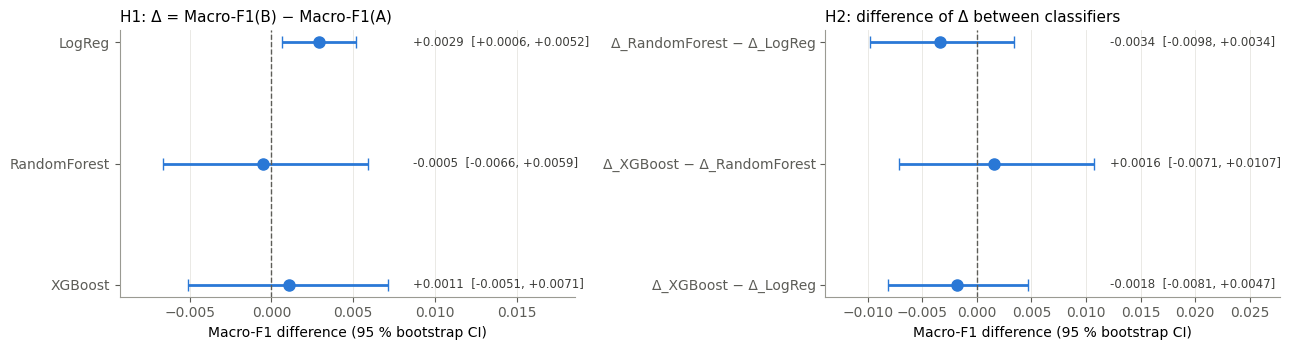

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1]})
for ax, tab, lab, title in [(axes[0], h1, "classifier", "H1: Δ = Macro-F1(B) − Macro-F1(A)"),
                            (axes[1], h2, "comparison", "H2: difference of Δ between classifiers")]:
    est_col = "Δ (B − A)" if lab == "classifier" else "difference"
    ys = np.arange(len(tab))[::-1]
    ax.errorbar(tab[est_col], ys, xerr=[tab[est_col] - tab["ci_low"], tab["ci_high"] - tab[est_col]],
                fmt="o", color="#2a78d6", markersize=8, capsize=4, linewidth=2)
    xt = tab["ci_high"].max() + 0.0015
    for yv, (e, lo, hi) in zip(ys, tab[[est_col, "ci_low", "ci_high"]].values):
        ax.text(xt, yv, f"{e:+.4f}  [{lo:+.4f}, {hi:+.4f}]", va="center", fontsize=8.5, color="#3d3d3a")
    ax.axvline(0, color="#5c5c57", linestyle="--", linewidth=1)
    ax.set_yticks(ys, tab[lab]); ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Macro-F1 difference (95 % bootstrap CI)")
    lim = max(abs(tab["ci_low"]).max(), abs(tab["ci_high"]).max())
    ax.set_xlim(-lim * 1.3, lim * 2.6); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIGURES / "phase5_h1_h2_forest.png", dpi=150, bbox_inches="tight")

## 4. Context for RQ3 — do the classifiers beat the persistence benchmark?

Not a pre-registered hypothesis, but needed to interpret RQ3. Two-sided test of Macro-F1(model) − Macro-F1(persistence), Holm-adjusted over the six models.

In [6]:
vp = []
for m in MODEL_NAMES:
    for c in ["A", "B"]:
        est = point[(m, c)]["macro_f1"] - point[("Persistence", "–")]["macro_f1"]
        dd = draws[(m, c)]["macro_f1"] - draws[("Persistence", "–")]["macro_f1"]
        vp.append({"model": m, "config": c, **BS.summarize(est, dd, "two-sided")})
vs_persist = pd.DataFrame(vp).rename(columns={"estimate": "Macro-F1 − persistence", "p_value": "p (two-sided)"})
vs_persist["p Holm"] = BS.holm(vs_persist["p (two-sided)"])
vs_persist["significant?"] = np.where(vs_persist["p Holm"] < ALPHA, "yes", "no")
vs_persist

,model,config,Macro-F1 − persistence,ci_low,ci_high,boot_se,p (two-sided),p Holm,significant?
0,LogReg,A,-0.0130,-0.0210,-0.0055,0.0040,0.0004,0.0024,yes
1,LogReg,B,-0.0101,-0.0182,-0.0025,0.0040,0.0072,0.0360,yes
2,RandomForest,A,0.0003,-0.0094,0.0101,0.0050,0.9626,1.0000,no
3,RandomForest,B,-0.0002,-0.0101,0.0099,0.0051,0.9694,1.0000,no
4,XGBoost,A,0.0072,-0.0048,0.0188,0.0061,0.2515,0.7546,no
5,XGBoost,B,0.0083,-0.0036,0.0200,0.0061,0.1780,0.7119,no


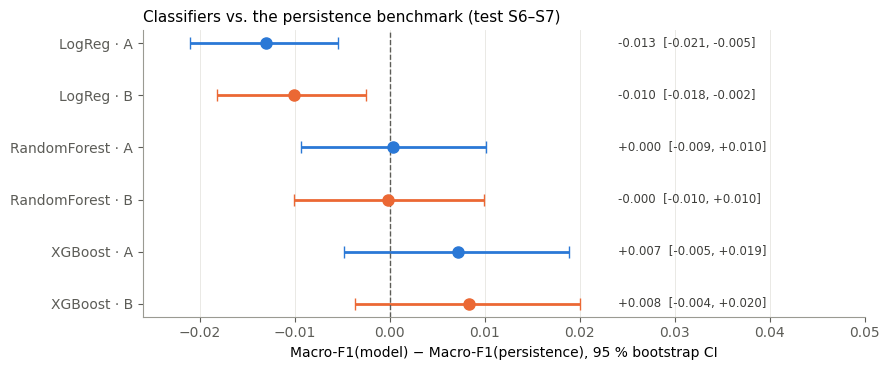

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
lab = vs_persist["model"] + " · " + vs_persist["config"]
ys = np.arange(len(vs_persist))[::-1]
cols = ["#2a78d6" if c == "A" else "#eb6834" for c in vs_persist["config"]]
xt = vs_persist["ci_high"].max() + 0.004
for yv, (e, lo, hi), col in zip(ys, vs_persist[["Macro-F1 − persistence", "ci_low", "ci_high"]].values, cols):
    ax.errorbar([e], [yv], xerr=[[e - lo], [hi - e]], fmt="o", color=col, markersize=8, capsize=4, linewidth=2)
    ax.text(xt, yv, f"{e:+.3f}  [{lo:+.3f}, {hi:+.3f}]", va="center", fontsize=8.5, color="#3d3d3a")
ax.axvline(0, color="#5c5c57", linestyle="--", linewidth=1)
ax.set_yticks(ys, lab); ax.set_xlabel("Macro-F1(model) − Macro-F1(persistence), 95 % bootstrap CI")
ax.set_title("Classifiers vs. the persistence benchmark (test S6–S7)", loc="left", fontsize=11)
ax.set_xlim(vs_persist["ci_low"].min() - 0.005, vs_persist["ci_high"].max() + 0.03); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIGURES / "phase5_vs_persistence.png", dpi=150, bbox_inches="tight")

## 5. Secondary metrics and subsets for Δ (B − A)

In [8]:
changers = y != seg
subsets = {"all test rows": None, "origin S6 only": (d["origin"] == "S6").values,
           "origin S7 only": (d["origin"] == "S7").values, "state changers only": changers}
rows = []
for sname, msk in subsets.items():
    pt, dr = (point, draws) if msk is None else boot_metrics(msk)
    for metric in ["macro_f1", "weighted_f1", "accuracy", "balanced_accuracy"]:
        if sname != "all test rows" and metric != "macro_f1" and sname != "state changers only":
            continue
        for m in MODEL_NAMES:
            est, dd = delta(metric, m, pt, dr)
            s = BS.summarize(est, dd, "two-sided")
            rows.append({"subset": sname, "metric": metric, "classifier": m, "Δ (B − A)": est,
                         "ci_low": s["ci_low"], "ci_high": s["ci_high"], "p (two-sided)": s["p_value"]})
secondary = pd.DataFrame(rows)
secondary.pivot_table(index=["subset", "metric"], columns="classifier",
                      values="Δ (B − A)", sort=False).round(4)

classifier                             LogReg  RandomForest  XGBoost
subset              metric                                          
all test rows       macro_f1           0.0029       -0.0005   0.0011
                    weighted_f1        0.0033        0.0001   0.0036
                    accuracy           0.0032        0.0009   0.0069
                    balanced_accuracy  0.0028        0.0011   0.0023
origin S6 only      macro_f1           0.0040       -0.0007  -0.0014
origin S7 only      macro_f1           0.0020       -0.0002   0.0026
state changers only macro_f1           0.0249        0.0138  -0.0066
                    weighted_f1        0.0326        0.0170  -0.0112
                    accuracy           0.0298        0.0134  -0.0105
                    balanced_accuracy  0.0242        0.0133  -0.0003

In [9]:
secondary

,subset,metric,classifier,Δ (B − A),ci_low,ci_high,p (two-sided)
0,all test rows,macro_f1,LogReg,0.0029,0.0006,0.0052,0.0132
1,all test rows,macro_f1,RandomForest,-0.0005,-0.0066,0.0059,0.8706
2,all test rows,macro_f1,XGBoost,0.0011,-0.0051,0.0071,0.7315
3,all test rows,weighted_f1,LogReg,0.0033,0.0007,0.0060,0.0156
4,all test rows,weighted_f1,RandomForest,0.0001,-0.0030,0.0032,0.9782
5,all test rows,weighted_f1,XGBoost,0.0036,0.0002,0.0071,0.0388
6,all test rows,accuracy,LogReg,0.0032,0.0006,0.0060,0.0196
7,all test rows,accuracy,RandomForest,0.0009,-0.0022,0.0041,0.6155
8,all test rows,accuracy,XGBoost,0.0069,0.0030,0.0108,0.0008
9,all test rows,balanced_accuracy,LogReg,0.0028,0.0005,0.0051,0.0168


## 6. Save

In [10]:
h1.to_csv(TABLES / "phase5_h1.csv", index=False)
h2.to_csv(TABLES / "phase5_h2.csv", index=False)
vs_persist.to_csv(TABLES / "phase5_vs_persistence.csv", index=False)
secondary.to_csv(TABLES / "phase5_secondary_deltas.csv", index=False)
print("saved")

saved


## Conclusions

**H1 — partially supported, with a very small effect.**
- Logistic Regression: Δ = +0.0029, 95 % CI [+0.0006, +0.0052], Holm-adjusted one-sided p = 0.020 → supported.
- Random Forest: Δ = −0.0005, CI [−0.0066, +0.0059], p = 0.73 → not supported.
- XGBoost: Δ = +0.0011, CI [−0.0051, +0.0071], p = 0.73 → not supported.
- Even where it is significant, the gain is about 0.3 Macro-F1 points. The upper CI limits show that, on these data, historical states add at most ≈ 0.005–0.007 Macro-F1 for any classifier.

**H2 — not supported.** None of the three pairwise differences of Δ is significant (Holm p ≥ 0.93); all CIs include 0. LR's gain is significant while those of RF and XGBoost are not, but the gains are not significantly *different* from each other — a significant and a non-significant result are not evidence of a difference.

**RQ3 in context.** No classifier is significantly better than persistence in Macro-F1 (XGBoost B: +0.008, CI [−0.004, +0.020]); Logistic Regression is significantly worse (−0.010 to −0.013). Accuracy is higher for all classifiers (Phase 4), and the benefit concentrates on customers who change state: there, history improves Logistic Regression (+0.025 Macro-F1, CI [+0.015, +0.035]) and Random Forest (+0.014, CI [+0.001, +0.027]) but not XGBoost (−0.007, CI [−0.019, +0.005]). The secondary subset results are exploratory and not multiplicity-adjusted.

**Interpretation.** In this dataset the current cumulative RFM profile and the current state already summarise most of a customer's trajectory, so explicit lagged states add little *on top of* them, even though past states are strongly informative when only states are known (Phase 3 Markov test). Limitations (proposal Section 3.8): single retailer, cumulative RFM accumulation, shorter final interval, and states that depend on the chosen RFM/K-Means design.